<a href="https://colab.research.google.com/github/harshithakathir28-wq/EX6_DL/blob/main/EX6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART A

In [4]:
# Experiment 6
# Roll No: 24BAD034

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

print("Sample Review:", x_train[0])
print("Sentiment:", y_train[0])

word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key for key, value in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

decoded_review = " ".join(
    reverse_word_index.get(i, "?") for i in x_train[0]
)

print("Decoded Review:", decoded_review)

max_length = 200

x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

print("Positive Reviews:", np.sum(y_train == 1))
print("Negative Reviews:", np.sum(y_train == 0))

Training Samples: 25000
Testing Samples: 25000
Sample Review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32

PART B

In [5]:
# Experiment 6
# Roll No: 24BAD034

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

model = Sequential()

model.add(Embedding(10000, 64, input_length=200))

model.add(LSTM(64))

model.add(Dense(1, activation='sigmoid'))

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

PART C

In [6]:
# Experiment 6
# Roll No: 24BAD034


history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.5286 - loss: 0.6897 - val_accuracy: 0.5526 - val_loss: 0.6810
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.5893 - loss: 0.6678 - val_accuracy: 0.6628 - val_loss: 0.6340
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6000 - loss: 0.6583 - val_accuracy: 0.5136 - val_loss: 0.6948
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6085 - loss: 0.6506 - val_accuracy: 0.5194 - val_loss: 0.7035
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6471 - loss: 0.6151 - val_accuracy: 0.5830 - val_loss: 0.6672
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5852 - loss: 0.6747
Test Loss: 0.6747413277626038
Test Accuracy: 0.5851600170135498


782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
              precision    recall  f1-score   support

           0       0.64      0.38      0.48     12500
           1       0.56      0.79      0.65     12500

    accuracy                           0.59     25000
   macro avg       0.60      0.59      0.57     25000
weighted avg       0.60      0.59      0.57     25000

Confusion Matrix:
[[4785 7715]
 [2656 9844]]


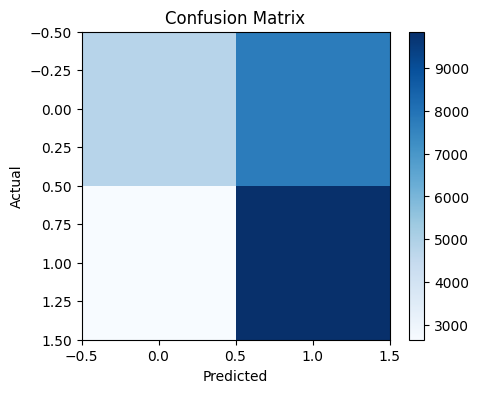

In [7]:
# Experiment 6
# Roll No: 24BAD034

from sklearn.metrics import classification_report, confusion_matrix

# Predict test data
y_pred = model.predict(x_test)

y_pred = (y_pred > 0.5).astype(int)

# Classification report
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()
plt.show()

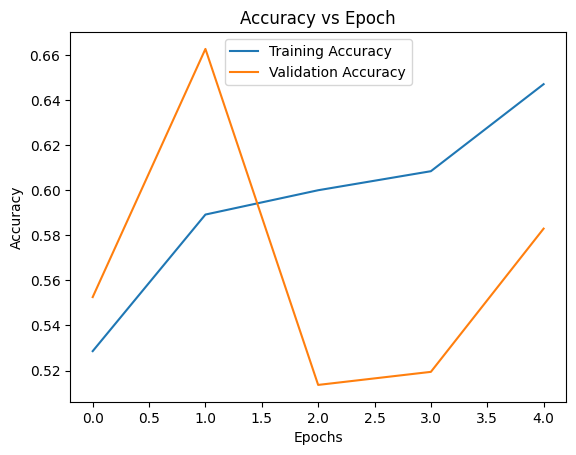

In [8]:
# Experiment 6
# Roll No: 24BAD034

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.title("Accuracy vs Epoch")

plt.legend()
plt.show()

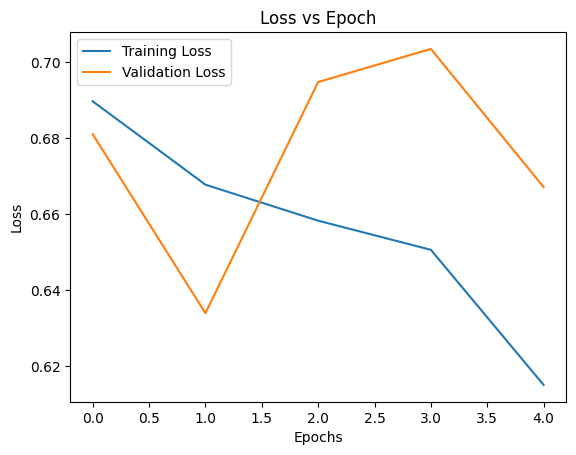

In [9]:
# Experiment 6
# Roll No: 24BAD034

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("Loss vs Epoch")

plt.legend()
plt.show()

PART D

In [10]:
# Experiment 6
# Roll No: 24BAD034

from tensorflow.keras.preprocessing.sequence import pad_sequences


def predict_sentiment(review):

    words = review.lower().split()

    word_index = imdb.get_word_index()

    sequence = [
        word_index.get(word, 2) + 3 if word in word_index else 2
        for word in words
    ]

    sequence = pad_sequences(
        [sequence],
        maxlen=200,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Probability:", prediction)
    print()


predict_sentiment("This movie was amazing and I really enjoyed it")

predict_sentiment("The movie was boring and very disappointing")

predict_sentiment("Excellent acting and wonderful story")

predict_sentiment("Worst movie with poor acting and terrible direction")

Review: This movie was amazing and I really enjoyed it
Predicted Sentiment: Positive
Probability: 0.5046827

Review: The movie was boring and very disappointing
Predicted Sentiment: Positive
Probability: 0.50468254

Review: Excellent acting and wonderful story
Predicted Sentiment: Positive
Probability: 0.5046827

Review: Worst movie with poor acting and terrible direction
Predicted Sentiment: Positive
Probability: 0.5046823

